In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import numpy as np
import astropy.units as u
import astropy.constants as const
%matplotlib inline

from matplotlib.ticker import AutoMinorLocator, MultipleLocator

                                                                                               
Vpeak - (3.1* (EB-V))

Multiplying by 3.1 gives Av or the extinction the amount its dimmed

For V1370 Aql do one for extinction = 0 and one for extinction = 0.41 plot as error bars


In [2]:
novae = pd.read_csv('/Users/isabellamolina/Desktop/NOVAE_CHAR2.csv', header = 0)



In [3]:
novae

,Name,t2,V_p,S_m,S_e,t_m,Period,Velocity,Mdot,Distance,D+err,D-err,EB-V,EB_err
0,V392 Per,3.00,5.60,5.226,0.262,32.000,81.9000,4100,1.100000e-06,3.20,0.6,-0.4,0.96,0.30
1,V407 Cyg,5.90,7.10,17.770,0.901,102.600,376938.0000,3200,2.900000e-06,4.52,2.5,-1.8,0.60,0.10
2,V1535 Sco,13.90,9.70,4.123,0.208,2.663,950.4000,4700,2.200000e-06,4.60,0.9,-0.6,0.69,0.19
3,V1534 Sco,5.60,11.60,13.300,0.665,14.650,12480.0000,4100,5.800000e-06,8.61,1.7,-1.1,1.10,NaN
4,V723 Cas,263.00,7.10,13.500,1.125,1697.000,16.6000,1750,2.400000e-06,4.70,1.0,-0.7,0.50,NaN
5,V5589 Sgr,4.50,9.06,3.423,0.173,62.300,38.2000,4800,3.200000e-06,7.50,0.9,-1.1,0.80,0.19
6,RS Oph,2.77,4.50,67.597,3.381,9.990,10886.4000,3700,6.100000e-07,2.71,0.2,-0.1,0.75,0.19
7,U Sco,1.00,7.50,0.115,0.029,32.530,29.5000,5000,3.700000e-06,7.50,2.0,-2.0,0.19,0.10
8,V745 Sco,6.20,9.40,8.930,0.450,25.600,3276.0000,4450,4.900000e-06,8.20,1.4,-1.3,0.69,0.20
9,V3890 Sgr,6.40,7.20,51.110,2.560,11.200,17942.4000,4200,4.200000e-06,6.04,1.3,-1.1,0.51,0.13


In [4]:
Extinction = novae['EB-V']
Extinc_err = novae['EB_err']

AV = 3.1 * Extinction

New_Vpeak = novae['V_p'] - AV

np.array(New_Vpeak)

array([2.624, 5.24 , 7.561, 8.19 , 5.55 , 6.58 , 2.175, 6.911, 7.261,
       5.619, 6.429])

In [5]:
AV1 = 3.1 * 0
AV2 = 3.1 * 0.41

New_V1 = novae['V_p'][10] - AV1
New_V2 = novae['V_p'][10] - AV2


In [6]:
New_VV = (New_V1 + New_V2)/2

In [7]:
new_err = New_V1 - New_VV

In [8]:
New_Vpeak

0     2.624
1     5.240
2     7.561
3     8.190
4     5.550
5     6.580
6     2.175
7     6.911
8     7.261
9     5.619
10    6.429
dtype: float64

## V Peak vs S max

In [9]:

Smax = novae['S_m']
Smax_err = novae["S_e"]

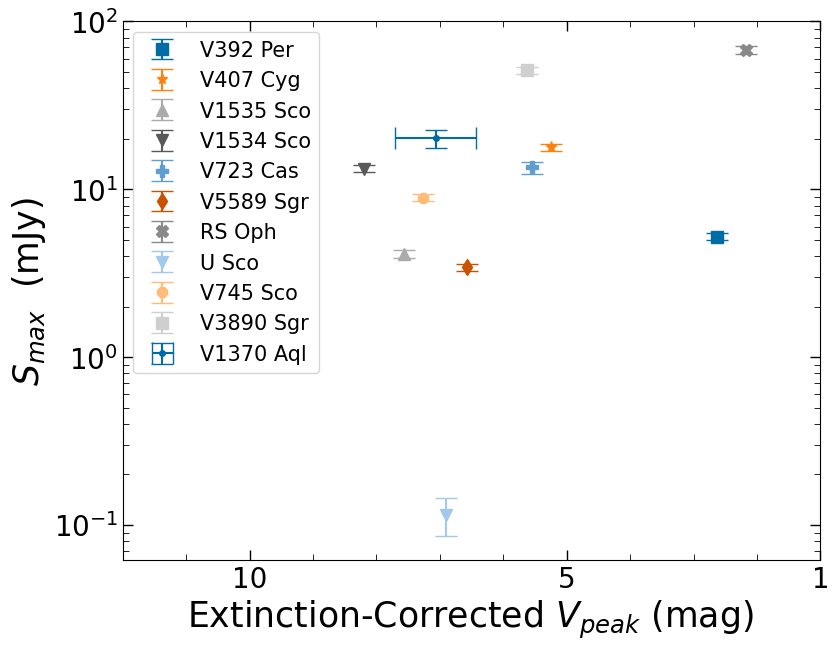

In [12]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)


ax.errorbar(New_Vpeak[0], Smax[0], yerr=Smax_err[0], label="V392 Per", fmt='s',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[1], Smax[1], yerr=Smax_err[1],label="V407 Cyg", fmt='*',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[2], Smax[2], yerr=Smax_err[2], fmt='^', label="V1535 Sco", capsize=8, markersize=8)

ax.errorbar(New_Vpeak[3], Smax[3], yerr=Smax_err[3], fmt='v', label="V1534 Sco", capsize=8, markersize=8)            

ax.errorbar(New_Vpeak[4], Smax[4], yerr=Smax_err[4], label="V723 Cas", fmt='P',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[5], Smax[5], yerr=Smax_err[5], label="V5589 Sgr", fmt='d', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[6], Smax[6], yerr=Smax_err[6], label="RS Oph", fmt='X', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[7], Smax[7], yerr=Smax_err[7], fmt='v', label="U Sco", capsize=8, markersize=8)

ax.errorbar(New_Vpeak[8], Smax[8], yerr=Smax_err[8], label="V745 Sco", fmt='8', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[9], Smax[9], yerr=Smax_err[9], label="V3890 Sgr", fmt='s', capsize=8, markersize=8)

ax.errorbar(New_VV, Smax[10], xerr=new_err, yerr=Smax_err[10], label="V1370 Aql",fmt='.',capsize=8, markersize=8)

ax.set_xticks([10,5,1], labels = ['10', '5', '1'], fontsize = 20)
ax.invert_xaxis()

ax.set_xlim([12,1])


ax.set_yscale('log')
ax.set_yticks([0.1,1, 10, 100], labels = [r'$10^{-1}$',r'$10^0$', r'$10^1$', r'$10^2$'], fontsize = 20)

ax.set_xlabel(r"Extinction-Corrected $V_{peak} $ (mag) ", fontsize=25)
ax.set_ylabel(r"$ S_{max} $  (mJy)", fontsize=25)


ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.xaxis.set_minor_locator(AutoMinorLocator(4))

plt.legend(fontsize = 15)
plt.show()
fig.savefig("Extinction_Corrected", dpi=300);


